# Assignment 2 — Clustering and Dimensionality Reduction

## 4DT910 — Data Mining

### 1. Introduction

This assignment investigates and compares dimensionality reduction and clustering techniques using three datasets from the UCI Machine Learning Repository:

1. Pen-Based Recognition of Handwritten Digits
2. Cardiotocography
3. Dry Bean Dataset

The following dimensionality reduction techniques are applied:

- Principal Component Analysis (PCA)
- t-Distributed Stochastic Neighbor Embedding (t-SNE)
- Uniform Manifold Approximation and Projection (UMAP)

Each technique reduces the original multidimensional dataset to two dimensions. The resulting representations are visualized using scatterplots colored according to their original class labels.

Three clustering algorithms are also investigated:

- K-Means
- DBSCAN
- Hierarchical Clustering

Clustering is performed on the original standardized multidimensional features. PCA is then used only to visualize the resulting clusters in two dimensions.

The results are compared using visualizations and cross-tabulation tables showing the relationship between the identified clusters and the original class labels.

The objective is to determine which techniques reveal the clearest class separation and produce the most meaningful clusters for each dataset.

In [51]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import umap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import (
    KMeans,
    DBSCAN,
    AgglomerativeClustering
)
from sklearn.neighbors import NearestNeighbors

# General settings
RANDOM_STATE = 42
SAMPLE_SIZE = 2500

# Dataset directory
DATA_DIR = Path("")

print("Libraries imported successfully.")

Libraries imported successfully.


### 1.1 General Methodology

The same general workflow is applied to all three datasets to make the comparisons consistent.

**Data preprocessing**

Each dataset is inspected for missing values, duplicate observations, and class distribution. Numerical features are separated from the original class labels and standardized using StandardScaler.

A stratified sample of up to 2,500 observations is selected from each dataset. This reduces the computational cost while preserving approximately the original class proportions.

**Dimensionality reduction**

PCA, t-SNE, and UMAP reduce each dataset to two dimensions. The scatterplots are colored according to the original classes to investigate how clearly each technique separates them.

**Clustering**

K-Means, DBSCAN, and Hierarchical Clustering are applied to the original standardized features.

K-Means and Hierarchical Clustering use the known number of classes as the requested number of clusters. DBSCAN identifies clusters based on density and can classify observations as noise.

The original class labels are not used to fit the dimensionality reduction or clustering models. They are only used for stratified sampling and to interpret the resulting visualizations and clusters.

**Evaluation**

The dimensionality reduction techniques are compared visually, focusing on class separation, overlapping regions, and the overall structures revealed.

The clustering techniques are evaluated by comparing their visualizations and examining cross-tabulation tables between the discovered clusters and the original class labels.

No quantitative quality metrics or extensive parameter investigations are performed, since these are additional requirements for Grade VG rather than Grade G.

In [52]:
def prepare_data(df, target_column, sample_size=SAMPLE_SIZE):
    """
    Separate features and labels, clean missing values,
    select a stratified sample, and standardize features.
    """

    df = df.copy()

    print("Original dataset shape:", df.shape)
    print("Missing values:", df.isna().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())

    # Remove observations with missing values
    df = df.dropna()

    # Remove duplicates
    df = df.drop_duplicates()

    # Separate features and labels
    X = df.drop(columns=[target_column])
    y = df[target_column]

    # Ensure features are numerical
    X = X.apply(pd.to_numeric, errors="raise")

    # Stratified sampling
    if len(df) > sample_size:
        X, _, y, _ = train_test_split(
            X,
            y,
            train_size=sample_size,
            stratify=y,
            random_state=RANDOM_STATE
        )

    # Standardize features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    print("\nPrepared dataset shape:", X_scaled.shape)

    print("\nClass distribution:")
    print(y.value_counts().sort_index())

    return X_scaled, y.to_numpy()

In [53]:
def run_dimensionality_reduction(X):

    # PCA
    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X)

    # t-SNE
    tsne = TSNE(
        n_components=2,
        perplexity=30,
        init="pca",
        learning_rate="auto",
        random_state=RANDOM_STATE
    )

    X_tsne = tsne.fit_transform(X)

    # UMAP
    umap_model = umap.UMAP(
        n_components=2,
        random_state=RANDOM_STATE
    )

    X_umap = umap_model.fit_transform(X)

    print(
        "PCA explained variance:",
        round(pca.explained_variance_ratio_.sum() * 100, 2),
        "%"
    )

    return {
        "PCA": X_pca,
        "t-SNE": X_tsne,
        "UMAP": X_umap
    }


def plot_dimensionality_reduction(embeddings, y, dataset_name):

    classes = np.unique(y)
    colors = plt.get_cmap("tab10", len(classes))

    fig, axes = plt.subplots(
        1, 3,
        figsize=(18, 5),
        constrained_layout=True
    )

    for ax, (name, coords) in zip(
        axes, embeddings.items()
    ):

        for i, cls in enumerate(classes):
            mask = y == cls

            ax.scatter(
                coords[mask, 0],
                coords[mask, 1],
                s=8,
                alpha=0.65,
                color=colors(i),
                label=str(cls)
            )

        ax.set_title(name)
        ax.set_xlabel("Dimension 1")
        ax.set_ylabel("Dimension 2")

    handles, labels = axes[0].get_legend_handles_labels()

    fig.legend(
        handles,
        labels,
        loc="outside right upper",
        title="Original class",
        markerscale=2
    )

    fig.suptitle(
        f"{dataset_name} — Dimensionality Reduction",
        fontsize=14
    )

    plt.show()

In [54]:
def run_clustering(X, n_classes):

    # K-Means
    kmeans = KMeans(
        n_clusters=n_classes,
        n_init=10,
        random_state=RANDOM_STATE
    )

    kmeans_labels = kmeans.fit_predict(X)

    # DBSCAN
    # Estimate eps using the distance to the 10th nearest
    # neighbor rather than assuming the same distance
    # threshold is appropriate for every dataset.
    min_samples = 10

    neighbors = NearestNeighbors(
        n_neighbors=min_samples
    )

    neighbors.fit(X)

    distances, _ = neighbors.kneighbors(X)

    eps = np.percentile(
        distances[:, -1],
        90
    )

    dbscan = DBSCAN(
        eps=eps,
        min_samples=min_samples
    )

    dbscan_labels = dbscan.fit_predict(X)

    # Hierarchical Clustering
    hierarchical = AgglomerativeClustering(
        n_clusters=n_classes,
        linkage="ward"
    )

    hierarchical_labels = hierarchical.fit_predict(X)

    results = {
        "K-Means": kmeans_labels,
        "DBSCAN": dbscan_labels,
        "Hierarchical": hierarchical_labels
    }

    print(f"DBSCAN eps: {eps:.3f}")
    print(f"DBSCAN min_samples: {min_samples}")

    for name, labels in results.items():

        n_clusters = len(set(labels) - {-1})
        n_noise = np.sum(labels == -1)

        print(f"\n{name}")
        print("Clusters:", n_clusters)
        print("Noise observations:", n_noise)

    return results


def plot_clustering(embeddings, clusterings, y, dataset_name):

    # Only use PCA for visualization
    X_pca = embeddings["PCA"]

    results = {
        "Original Classes": y,
        **clusterings
    }

    fig, axes = plt.subplots(
        1, 4,
        figsize=(19, 5),
        constrained_layout=True
    )

    for ax, (name, labels) in zip(
        axes, results.items()
    ):

        unique_labels = np.unique(labels)
        valid_labels = unique_labels[unique_labels != -1]

        cmap = plt.get_cmap(
            "tab20",
            max(len(valid_labels), 1)
        )

        for i, label in enumerate(valid_labels):

            mask = labels == label

            ax.scatter(
                X_pca[mask, 0],
                X_pca[mask, 1],
                s=8,
                alpha=0.65,
                color=cmap(i),
                label=str(label)
            )

        # DBSCAN noise observations
        if -1 in unique_labels:

            noise = labels == -1

            ax.scatter(
                X_pca[noise, 0],
                X_pca[noise, 1],
                s=8,
                color="black",
                alpha=0.5,
                label="Noise"
            )

        ax.set_title(name)
        ax.set_xlabel("PCA 1")
        ax.set_ylabel("PCA 2")

    fig.suptitle(
        f"{dataset_name} — Clustering",
        fontsize=14
    )

    plt.show()


def compare_clusters(clusterings, y):

    for name, labels in clusterings.items():

        print(f"\n{name} — Cluster/Class Comparison")

        table = pd.crosstab(
            pd.Series(labels, name="Cluster"),
            pd.Series(y, name="Original Class")
        )

        display(table)

        print("Dominant class in each cluster:")
        print(table.idxmax(axis=1).to_dict())

## 2. Pen-Based Recognition of Handwritten Digits

### 2.1 Dataset Description

The Pen-Based Recognition of Handwritten Digits dataset is available from the UCI Machine Learning Repository.

The dataset contains handwritten digits represented using 16 numerical attributes corresponding to eight sampled pairs of coordinates along the handwriting trajectory.

Each observation belongs to one of ten classes representing digits 0–9.

The dataset is provided in separate training and test files. These are combined because the objective is unsupervised data mining rather than classification.

The original digit labels are retained for visualizing the dimensionality reduction results and comparing the clusters with the known digit classes.

The numerical features are standardized before applying the algorithms.

In [55]:
# Pen Digits dataset directory
pen_dir = (
    DATA_DIR /
    "pen+based+recognition+of+handwritten+digits"
)

# Column names
pen_columns = [
    f"coordinate_{i+1}" for i in range(16)
] + ["digit"]

# Read training data
pen_train = pd.read_csv(
    pen_dir / "pendigits.tra",
    header=None,
    names=pen_columns
)

# Read test data
pen_test = pd.read_csv(
    pen_dir / "pendigits.tes",
    header=None,
    names=pen_columns
)

# Combine both datasets
pen_df = pd.concat(
    [pen_train, pen_test],
    ignore_index=True
)

display(pen_df.head())

# Prepare data
X_pen, y_pen = prepare_data(
    pen_df,
    target_column="digit"
)

,coordinate_1,coordinate_2,coordinate_3,coordinate_4,coordinate_5,coordinate_6,coordinate_7,coordinate_8,coordinate_9,coordinate_10,coordinate_11,coordinate_12,coordinate_13,coordinate_14,coordinate_15,coordinate_16,digit
0,47,100,27,81,57,37,26,0,0,23,56,53,100,90,40,98,8
1,0,89,27,100,42,75,29,45,15,15,37,0,69,2,100,6,2
2,0,57,31,68,72,90,100,100,76,75,50,51,28,25,16,0,1
3,0,100,7,92,5,68,19,45,86,34,100,45,74,23,67,0,4
4,0,67,49,83,100,100,81,80,60,60,40,40,33,20,47,0,1


Original dataset shape: (10992, 17)
Missing values: 0
Duplicate rows: 0

Prepared dataset shape: (2500, 16)

Class distribution:
digit
0    260
1    260
2    260
3    240
4    260
5    240
6    240
7    260
8    240
9    240
Name: count, dtype: int64


### 2.2 Dimensionality Reduction

PCA, t-SNE, and UMAP are applied to the standardized 16-dimensional dataset.

PCA identifies two directions capturing the greatest variance in the data, while t-SNE and UMAP focus on preserving local relationships between observations.

The resulting scatterplots are colored using the original digit labels.

The visualizations are compared to determine which method provides the clearest separation between handwritten digit classes and which structures become visible after dimensionality reduction.

c:\Users\Kim\AppData\Local\Programs\Python\Python314\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


PCA explained variance: 49.63 %


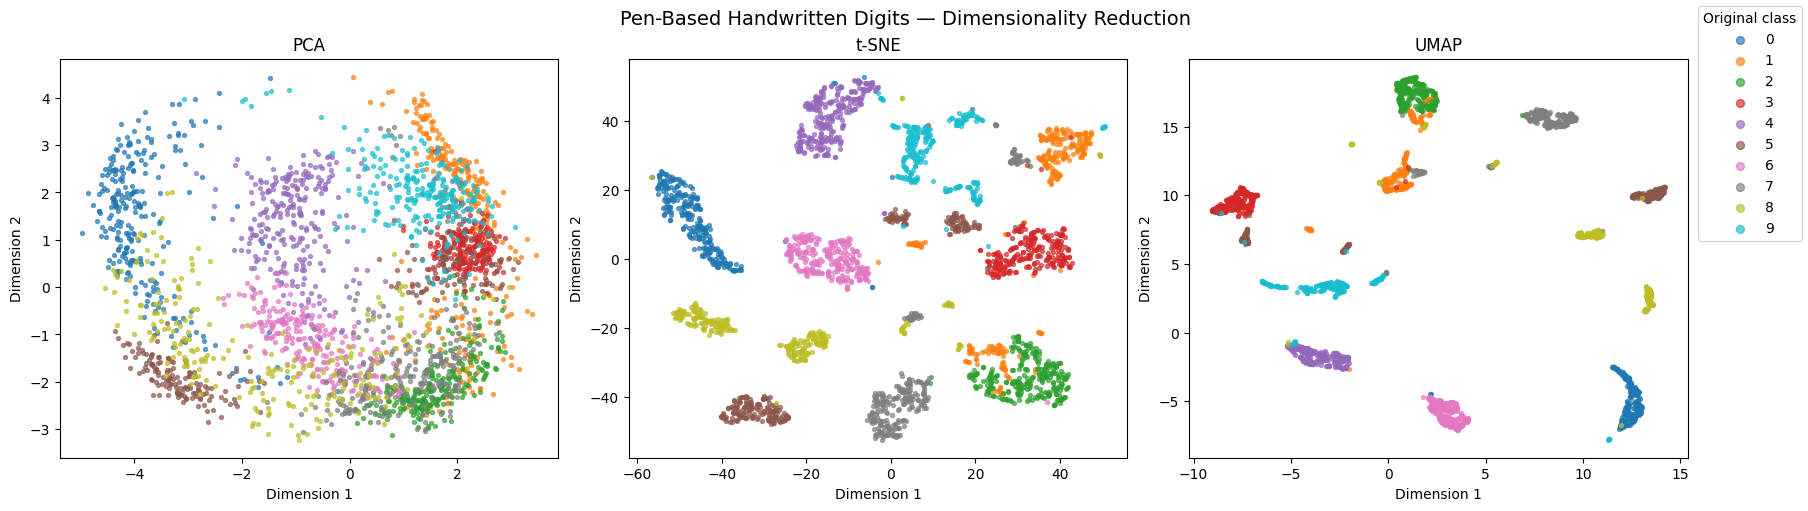

In [56]:
# Apply dimensionality reduction
pen_embeddings = run_dimensionality_reduction(X_pen)

# Visualize the results
plot_dimensionality_reduction(
    pen_embeddings,
    y_pen,
    "Pen-Based Handwritten Digits"
)

### 2.3 Dimensionality Reduction Discussion

**PCA**

PCA produces a relatively continuous distribution of observations, with considerable overlap between digit classes. Some digits occupy recognizable regions, such as digit 0 toward the left and digit 4 near the center, but many classes overlap in other regions.

The first two principal components explain 49.63% of the total variance. This indicates that a considerable amount of the original variation is not represented in the two-dimensional PCA projection.

**t-SNE**

t-SNE produces substantially clearer separation between digit classes than PCA. Several classes form recognizable groups, including digits 0, 4, 5, and 6.

However, some overlap remains. For example, digits 1 and 2 occupy overlapping regions toward the lower-right side of the visualization. Some digit classes are also distributed across multiple smaller groups.

This suggests that t-SNE captures local similarities between handwritten digits more effectively than the linear PCA representation.

**UMAP**

UMAP produces the clearest overall separation between digit classes. Most digits form compact groups with relatively little overlap.

Digits 0, 3, 5, 6, and 7 form particularly recognizable regions. However, digits 1 and 2 overlap in part of the visualization, and some classes are divided into smaller disconnected groups.

UMAP reveals a structure consisting of several well-separated groups rather than the continuous and overlapping distribution observed with PCA.

**Comparison**

PCA captures the main directions of variation but has difficulty separating the ten digit classes.

Both t-SNE and UMAP reveal more distinct groups, suggesting that nonlinear dimensionality reduction is better suited to visualizing the local structure of this dataset.

UMAP provides the clearest overall class separation, followed by t-SNE, while PCA shows the most overlap.

These conclusions are based on visual inspection of the two-dimensional representations. The apparent distances between groups, particularly for t-SNE and UMAP, should not be interpreted as exact distances in the original feature space.### 2.3 Dimensionality Reduction Discussion

**PCA**

PCA produces a relatively continuous distribution of observations, with considerable overlap between digit classes. Some digits occupy recognizable regions, such as digit 0 toward the left and digit 4 near the center, but many classes overlap in other regions.

The first two principal components explain 49.63% of the total variance. This indicates that a considerable amount of the original variation is not represented in the two-dimensional PCA projection.

**t-SNE**

t-SNE produces substantially clearer separation between digit classes than PCA. Several classes form recognizable groups, including digits 0, 4, 5, and 6.

However, some overlap remains. For example, digits 1 and 2 occupy overlapping regions toward the lower-right side of the visualization. Some digit classes are also distributed across multiple smaller groups.

This suggests that t-SNE captures local similarities between handwritten digits more effectively than the linear PCA representation.

**UMAP**

UMAP produces the clearest overall separation between digit classes. Most digits form compact groups with relatively little overlap.

Digits 0, 3, 5, 6, and 7 form particularly recognizable regions. However, digits 1 and 2 overlap in part of the visualization, and some classes are divided into smaller disconnected groups.

UMAP reveals a structure consisting of several well-separated groups rather than the continuous and overlapping distribution observed with PCA.

**Comparison**

PCA captures the main directions of variation but has difficulty separating the ten digit classes.

Both t-SNE and UMAP reveal more distinct groups, suggesting that nonlinear dimensionality reduction is better suited to visualizing the local structure of this dataset.

UMAP provides the clearest overall class separation, followed by t-SNE, while PCA shows the most overlap.

These conclusions are based on visual inspection of the two-dimensional representations. The apparent distances between groups, particularly for t-SNE and UMAP, should not be interpreted as exact distances in the original feature space.

### 2.4 Clustering

Three clustering techniques are applied to the standardized 16-dimensional feature space.

K-Means and Hierarchical Clustering are configured to identify ten clusters, corresponding to the ten known digit classes.

DBSCAN identifies density-based clusters without requiring the number of groups to be specified.

The cluster assignments are visualized using the two-dimensional PCA projection. The clustering algorithms themselves are not applied to the reduced data.

The resulting clusters are then compared with the original digit labels.

DBSCAN eps: 2.101
DBSCAN min_samples: 10

K-Means
Clusters: 10
Noise observations: 0

DBSCAN
Clusters: 3
Noise observations: 100

Hierarchical
Clusters: 10
Noise observations: 0


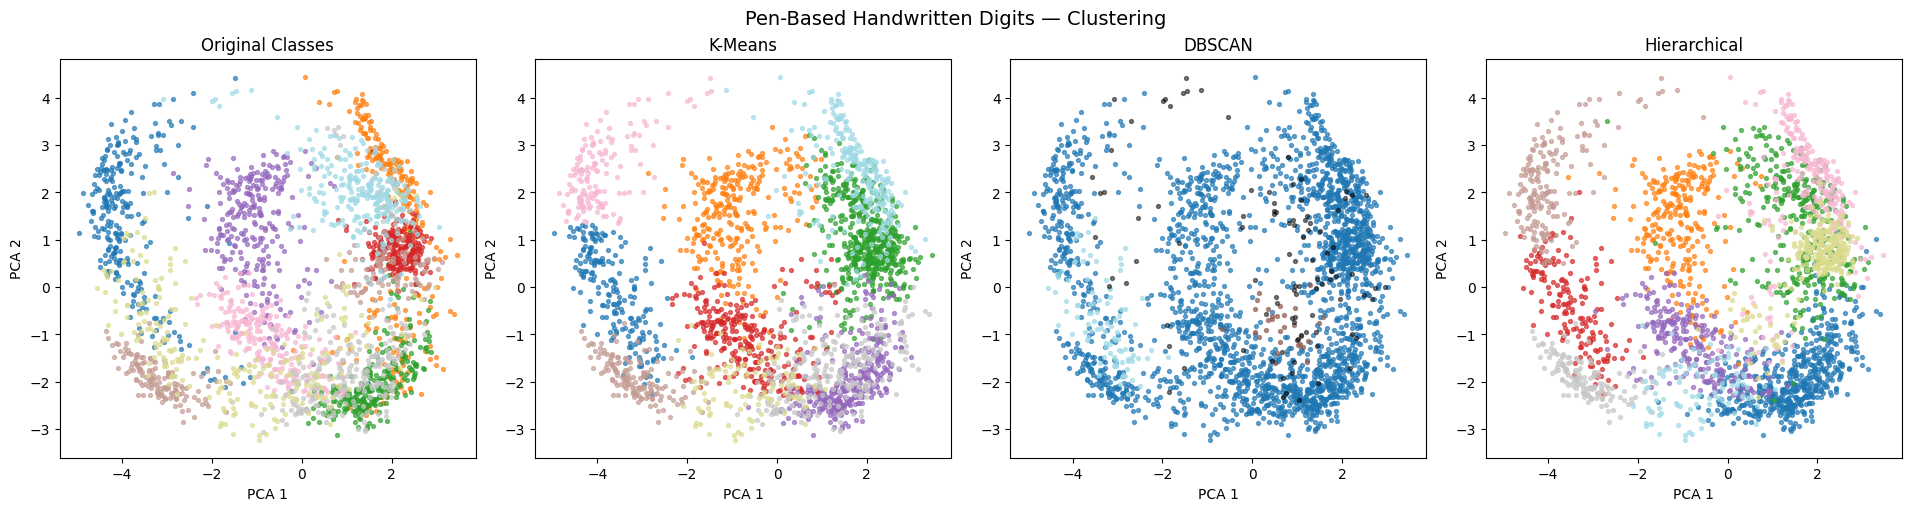


K-Means — Cluster/Class Comparison


Original Class,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
0,104,0,0,0,0,0,0,0,94,0
1,2,0,0,0,238,0,0,0,0,37
2,0,30,0,233,1,85,0,4,9,163
3,12,3,0,0,19,13,239,2,0,0
4,2,57,244,0,0,0,1,2,11,1
5,0,0,0,0,0,141,0,1,9,0
6,140,0,0,0,0,0,0,0,3,6
7,0,13,14,0,0,0,0,213,12,0
8,0,0,0,0,0,1,0,1,97,0


Dominant class in each cluster:
{0: 0, 1: 4, 2: 3, 3: 6, 4: 2, 5: 5, 6: 0, 7: 7, 8: 8, 9: 1}

DBSCAN — Cluster/Class Comparison


Original Class,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
-1,9,8,0,0,2,0,3,0,40,38
0,251,252,260,240,258,240,237,237,98,202
1,0,0,0,0,0,0,0,23,7,0
2,0,0,0,0,0,0,0,0,95,0


Dominant class in each cluster:
{-1: 8, 0: 2, 1: 7, 2: 8}

Hierarchical — Cluster/Class Comparison


Original Class,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
0,0,67,260,1,0,0,0,200,6,0
1,3,0,0,0,255,0,0,0,0,1
2,4,18,0,3,5,96,0,6,0,208
3,68,0,0,0,0,0,0,0,103,0
4,13,0,0,0,0,0,240,0,0,0
5,172,0,0,0,0,0,0,0,1,8
6,0,172,0,3,0,0,0,30,19,23
7,0,0,0,0,0,141,0,0,4,0
8,0,3,0,233,0,2,0,23,12,0


Dominant class in each cluster:
{0: 2, 1: 4, 2: 9, 3: 8, 4: 6, 5: 0, 6: 1, 7: 5, 8: 3, 9: 8}


In [57]:
# Apply clustering
pen_clusters = run_clustering(
    X_pen,
    n_classes=len(np.unique(y_pen))
)

# Visualize clusters
plot_clustering(
    pen_embeddings,
    pen_clusters,
    y_pen,
    "Pen-Based Handwritten Digits"
)

# Compare clusters with original labels
compare_clusters(
    pen_clusters,
    y_pen
)

### 2.5 Clustering Discussion

**K-Means**

K-Means produces ten clusters, matching the number of known digit classes.

Several clusters are dominated by individual digits. For example, cluster 4 contains 244 observations of digit 2, cluster 3 contains 239 observations of digit 6, and cluster 7 contains 213 observations of digit 7.

However, some clusters contain mixtures of different classes. Cluster 2 contains 233 observations of digit 3, 163 of digit 9, and 85 of digit 5. This indicates that the algorithm considers some of these handwritten digits similar.

Digit 0 is also divided between clusters 0 and 6, showing that observations belonging to the same class do not necessarily form a single cluster.

Overall, K-Means identifies several meaningful groups but does not perfectly reproduce the original digit classes.

**DBSCAN**

DBSCAN identifies three clusters and classifies 100 observations as noise, using an estimated eps value of 2.101 and min_samples=10.

Cluster 0 contains 2,275 observations representing all ten digit classes. Cluster 1 contains 30 observations, mainly digits 7 and 8, while cluster 2 contains 95 observations, all belonging to digit 8.

The noise observations mainly consist of digits 8 and 9.

Although DBSCAN identifies a relatively distinct group of digit 8 observations, it fails to separate most other digit classes because the majority of observations are assigned to one large cluster.

This indicates that the selected density threshold is not suitable for distinguishing most handwritten digit classes.

**Hierarchical Clustering**

Hierarchical Clustering produces ten clusters using Ward linkage.

Several clusters correspond closely to individual digit classes. For example, cluster 1 contains 255 observations of digit 4, cluster 4 contains 240 observations of digit 6, and cluster 8 contains 233 observations of digit 3.

However, some clusters combine different classes. Cluster 0 contains all 260 observations of digit 2 and 200 observations of digit 7, while cluster 2 contains substantial numbers of digits 5 and 9.

The results show that Hierarchical Clustering can identify meaningful digit groups but also combines classes with similar handwriting characteristics.

**Comparison**

K-Means and Hierarchical Clustering both produce considerably more meaningful results than DBSCAN for this dataset.

K-Means identifies several relatively distinct digit groups, while Hierarchical Clustering successfully isolates some classes but also combines large portions of different digit classes.

DBSCAN produces one dominant cluster containing most observations, making it less useful for separating the original classes with the selected parameters.

Based on the cross-tabulation tables and visualizations, K-Means appears to produce the most meaningful overall clustering for Pen Digits, although Hierarchical Clustering provides comparable results for several individual classes.

## 3. Cardiotocography

### 3.1 Dataset Description

The Cardiotocography dataset is obtained from the UCI Machine Learning Repository.

The dataset contains measurements extracted from fetal cardiotocograms, which record fetal heart rate and uterine contractions.

The analysis uses 21 numerical features describing characteristics such as baseline fetal heart rate, accelerations, decelerations, variability, and histogram measurements.

The original fetal-state labels are represented by the NSP attribute, which contains three categories:

- 1: Normal
- 2: Suspect
- 3: Pathologic

The objective is to investigate whether these three classes form distinguishable groups in the multidimensional feature space.

The NSP labels are used only for sampling, visualization, and interpretation. The alternative CLASS classification attribute and non-feature metadata are excluded from the analysis.

In [58]:
# Cardiotocography dataset directory
ctg_dir = DATA_DIR / "cardiotocography"

ctg_file = ctg_dir / "CTG.xls"

# The 21 numerical features
ctg_features = [
    "LB", "AC", "FM", "UC", "DL", "DS", "DP",
    "ASTV", "MSTV", "ALTV", "MLTV",
    "Width", "Min", "Max", "Nmax", "Nzeros",
    "Mode", "Mean", "Median", "Variance", "Tendency"
]

# Read available worksheets
ctg_excel = pd.ExcelFile(ctg_file)

print("Available worksheets:", ctg_excel.sheet_names)

ctg_df = None

# Find the worksheet containing the required features
for sheet in ctg_excel.sheet_names:

    raw = pd.read_excel(
        ctg_excel,
        sheet_name=sheet,
        header=None
    )

    for row_index in range(min(15, len(raw))):

        header = [
            str(value).strip()
            if pd.notna(value) else ""
            for value in raw.iloc[row_index]
        ]

        required = ctg_features + ["NSP"]

        if set(required).issubset(set(header)):

            # Select columns by their positions
            # to avoid duplicate column names
            column_indices = [
                header.index(name)
                for name in required
            ]

            ctg_df = raw.iloc[
                row_index + 1:,
                column_indices
            ].copy()

            # Assign unique column names
            ctg_df.columns = required

            print("Selected worksheet:", sheet)
            print("Header row:", row_index + 1)

            break

    if ctg_df is not None:
        break

if ctg_df is None:
    raise ValueError(
        "Could not find the expected "
        "Cardiotocography columns."
    )

# Convert columns to numerical values
ctg_df = ctg_df.apply(
    pd.to_numeric,
    errors="coerce"
)

# Remove completely empty rows
ctg_df = ctg_df.dropna(how="all")

# Keep observations with a valid NSP label
ctg_df = ctg_df[
    ctg_df["NSP"].isin([1, 2, 3])
].copy()

ctg_df["NSP"] = ctg_df["NSP"].astype(int)

display(ctg_df.head())

# Prepare data
X_ctg, y_ctg = prepare_data(
    ctg_df,
    target_column="NSP"
)

Available worksheets: ['Description', 'Data', 'Raw Data']
Selected worksheet: Data
Header row: 2


,LB,AC,FM,UC,DL,DS,DP,ASTV,MSTV,ALTV,...,Min,Max,Nmax,Nzeros,Mode,Mean,Median,Variance,Tendency,NSP
2,120.0,0.0,0.0,0.0,0.0,0.0,0.0,73.0,0.5,43.0,...,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,2
3,132.0,4.0,0.0,4.0,2.0,0.0,0.0,17.0,2.1,0.0,...,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,1
4,133.0,2.0,0.0,5.0,2.0,0.0,0.0,16.0,2.1,0.0,...,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,1
5,134.0,2.0,0.0,6.0,2.0,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,1
6,132.0,4.0,0.0,5.0,0.0,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,1


Original dataset shape: (2126, 22)
Missing values: 0
Duplicate rows: 14

Prepared dataset shape: (2112, 21)

Class distribution:
NSP
1    1646
2     292
3     174
Name: count, dtype: int64


### 3.2 Dimensionality Reduction

PCA, t-SNE, and UMAP are applied to the standardized Cardiotocography dataset.

The objective is to investigate whether the three fetal-state categories can be distinguished using two-dimensional representations of the original measurements.

PCA emphasizes directions of maximum variance, while t-SNE and UMAP emphasize local relationships between observations.

The observations are colored according to their original NSP labels.

The resulting visualizations are compared to identify the technique that provides the clearest class separation and to investigate whether different techniques reveal different structures.

c:\Users\Kim\AppData\Local\Programs\Python\Python314\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


PCA explained variance: 45.3 %


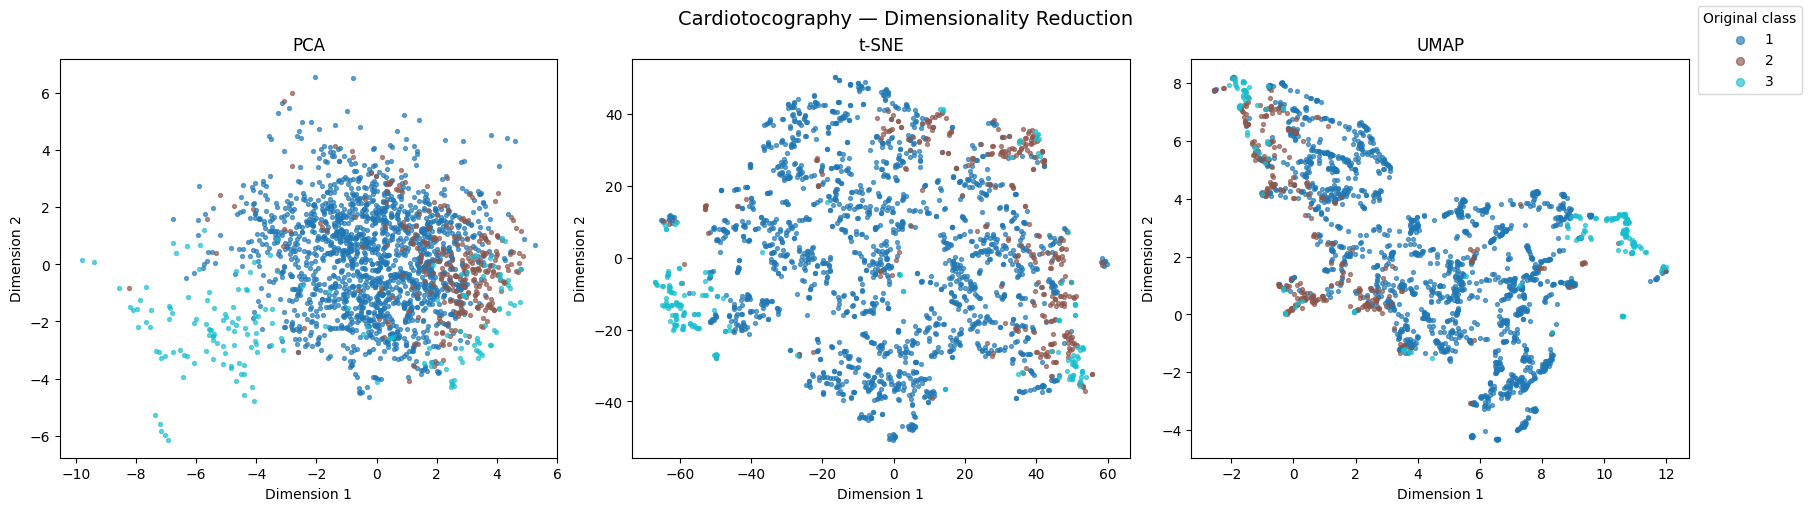

In [59]:
# Apply dimensionality reduction
ctg_embeddings = run_dimensionality_reduction(X_ctg)

# Visualize results
plot_dimensionality_reduction(
    ctg_embeddings,
    y_ctg,
    "Cardiotocography"
)

### 3.3 Dimensionality Reduction Discussion

**PCA**

PCA produces a continuous distribution with substantial overlap between the three NSP classes.

Normal observations (class 1) dominate the central region of the visualization. Suspect observations (class 2) are more concentrated toward the right, while Pathologic observations (class 3) appear more frequently toward the left and lower parts of the plot.

However, none of the three classes is completely separated from the others.

The first two principal components explain 45.30% of the total variance, indicating that more than half of the original variance is not represented in the two-dimensional projection.

**t-SNE**

t-SNE produces a more spread-out representation containing several smaller groups and irregular structures.

Normal observations are distributed across much of the visualization, while Suspect observations appear more frequently toward the right side. Some Pathologic observations form groups toward the left, although they still overlap with Normal observations.

Compared with PCA, t-SNE reveals more detailed local structures, but the three NSP classes remain substantially mixed.

**UMAP**

UMAP produces a more structured representation with several curved and elongated groups.

Normal observations remain distributed across most of the visualization, while some Pathologic observations appear toward the upper-right region. Suspect observations are mixed with both Normal and Pathologic observations.

Although UMAP reveals more clearly defined local structures than PCA, it does not produce three distinct groups corresponding to the original NSP classes.

**Comparison**

All three dimensionality reduction techniques show considerable overlap between the Normal, Suspect, and Pathologic categories.

PCA provides a relatively simple representation of the overall distribution. t-SNE reveals more detailed local groups, while UMAP produces more recognizable curved and separated structures.

UMAP appears to provide the clearest representation of local structures, but no technique achieves clear separation of all three classes.

This suggests that the differences between fetal-state categories cannot be represented as three completely separate groups using these two-dimensional projections.

### 3.4 Clustering

K-Means, DBSCAN, and Hierarchical Clustering are applied to the standardized Cardiotocography features.

K-Means and Hierarchical Clustering are configured to identify three clusters, corresponding to the three NSP classes.

DBSCAN identifies dense groups without specifying the number of clusters.

All clustering algorithms operate on the original standardized multidimensional data.

The resulting cluster assignments are visualized using PCA and compared against the original NSP labels through cross-tabulation tables.

DBSCAN eps: 3.501
DBSCAN min_samples: 10

K-Means
Clusters: 3
Noise observations: 0

DBSCAN
Clusters: 1
Noise observations: 111

Hierarchical
Clusters: 3
Noise observations: 0


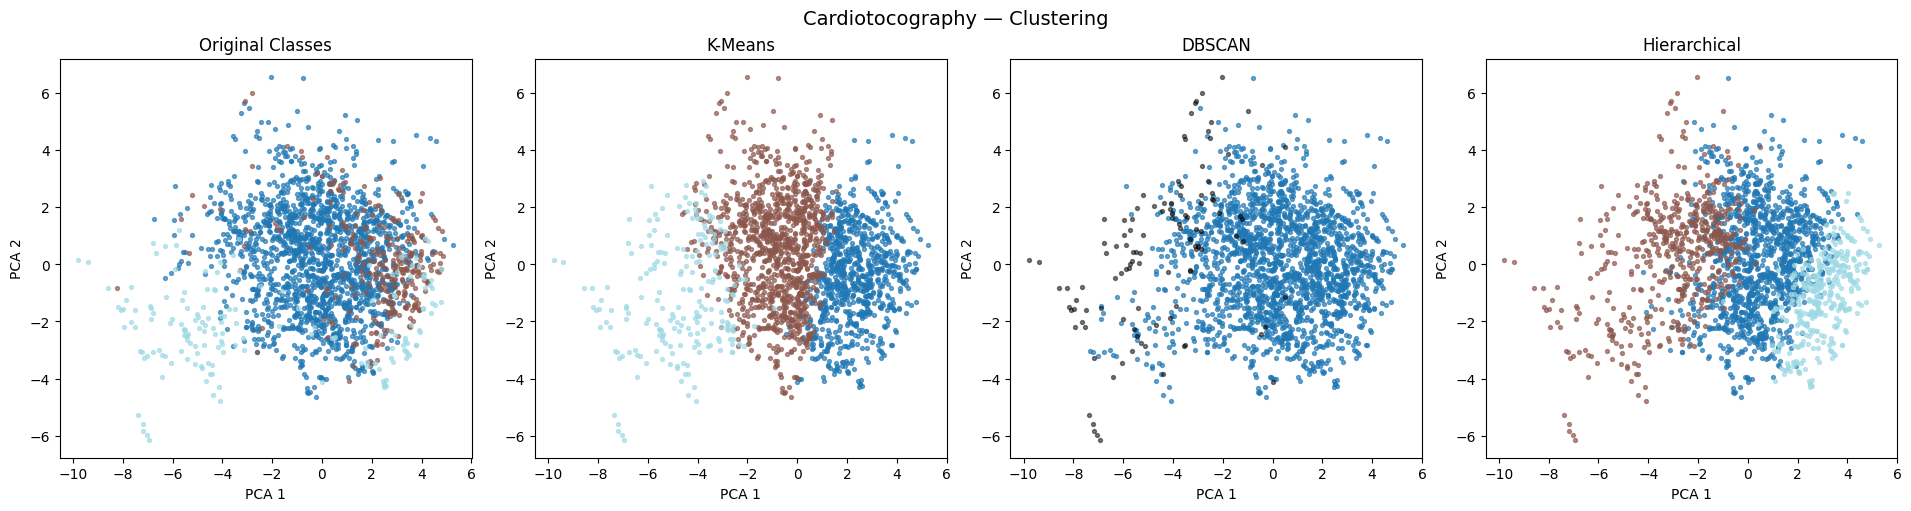


K-Means — Cluster/Class Comparison


Original Class,1,2,3
Cluster,,,
0,530,240,64
1,1023,41,5
2,93,11,105


Dominant class in each cluster:
{0: 1, 1: 1, 2: 3}

DBSCAN — Cluster/Class Comparison


Original Class,1,2,3
Cluster,,,
-1,54,14,43
0,1592,278,131


Dominant class in each cluster:
{-1: 1, 0: 1}

Hierarchical — Cluster/Class Comparison


Original Class,1,2,3
Cluster,,,
0,1093,110,14
1,416,19,104
2,137,163,56


Dominant class in each cluster:
{0: 1, 1: 1, 2: 2}


In [60]:
# Apply clustering
ctg_clusters = run_clustering(
    X_ctg,
    n_classes=len(np.unique(y_ctg))
)

# Visualize clusters
plot_clustering(
    ctg_embeddings,
    ctg_clusters,
    y_ctg,
    "Cardiotocography"
)

# Compare clusters with original labels
compare_clusters(
    ctg_clusters,
    y_ctg
)

### 3.5 Clustering Discussion

**K-Means**

K-Means produces three clusters, corresponding to the number of known NSP classes.

Cluster 1 contains 1,023 Normal observations, 41 Suspect observations, and only 5 Pathologic observations. This makes it a relatively homogeneous Normal-dominated cluster.

Cluster 2 contains 105 Pathologic observations, compared with 93 Normal and 11 Suspect observations. This indicates that K-Means identifies a group containing a relatively high proportion of Pathologic observations.

However, cluster 0 contains a mixture of all three classes, including 530 Normal, 240 Suspect, and 64 Pathologic observations.

K-Means therefore identifies some meaningful differences between observations, but the resulting clusters do not correspond perfectly to the original fetal-state categories.

**DBSCAN**

DBSCAN identifies only one cluster and classifies 111 observations as noise, using an estimated eps value of 3.501 and min_samples=10.

The main cluster contains 2,001 observations from all three NSP classes, including 1,592 Normal, 278 Suspect, and 131 Pathologic observations.

The noise group contains 54 Normal, 14 Suspect, and 43 Pathologic observations.

Although Pathologic observations are relatively common among the detected noise points, DBSCAN does not successfully separate the three fetal-state categories into meaningful clusters.

With the selected parameters, almost all observations are assigned to one large group.

**Hierarchical Clustering**

Hierarchical Clustering produces three clusters using Ward linkage.

Cluster 0 contains 1,093 Normal observations, 110 Suspect observations, and 14 Pathologic observations, making it predominantly Normal.

Cluster 2 contains 137 Normal, 163 Suspect, and 56 Pathologic observations. This group contains the largest concentration of Suspect observations.

Cluster 1 contains 416 Normal observations, 19 Suspect observations, and 104 Pathologic observations.

The results indicate that Hierarchical Clustering identifies groups associated with different fetal-state categories, although substantial overlap remains.

**Comparison**

Both K-Means and Hierarchical Clustering identify meaningful differences between the Cardiotocography observations, while DBSCAN largely combines all observations into one cluster.

K-Means identifies a relatively homogeneous Normal-dominated cluster and a separate group containing a high proportion of Pathologic observations.

Hierarchical Clustering also identifies a Normal-dominated group, while another cluster contains a relatively high concentration of Suspect observations.

Based on the cross-tabulation tables, K-Means appears slightly more meaningful overall because it identifies a relatively distinct Pathologic-enriched group while also preserving a large Normal-dominated group.

However, Hierarchical Clustering provides a comparable alternative, and neither method successfully separates all three original classes.

The substantial class imbalance, with Normal observations representing the majority of the dataset, may contribute to the difficulty of identifying distinct groups for the less common classes.

## 4. Dry Bean Dataset

### 4.1 Dataset Description

The Dry Bean dataset is obtained from the UCI Machine Learning Repository.

The dataset contains measurements extracted from images of dry beans belonging to seven varieties:

- Barbunya
- Bombay
- Cali
- Dermason
- Horoz
- Seker
- Sira

Each bean is represented by 16 numerical features describing geometric characteristics such as area, perimeter, axis lengths, compactness, roundness, and shape factors.

The objective is to investigate whether the seven bean varieties form distinguishable groups based on their numerical characteristics.

The original class labels are excluded from the dimensionality reduction and clustering algorithms, but retained for visualization and comparison.

The numerical features are standardized before analysis to prevent variables with larger numerical scales from dominating the distance-based techniques.

In [61]:
# Dry Bean dataset directory
bean_dir = (
    DATA_DIR /
    "dry+bean+dataset" /
    "DryBeanDataset"
)

bean_file = bean_dir / "Dry_Bean_Dataset.xlsx"

# Read dataset
bean_df = pd.read_excel(
    bean_file,
    sheet_name="Dry_Beans_Dataset"
)

print("Dataset shape:", bean_df.shape)
print("Columns:", bean_df.columns.tolist())

display(bean_df.head())

# Prepare data
X_bean, y_bean = prepare_data(
    bean_df,
    target_column="Class"
)

Dataset shape: (13611, 17)
Columns: ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


Original dataset shape: (13611, 17)
Missing values: 0
Duplicate rows: 68

Prepared dataset shape: (2500, 16)

Class distribution:
Class
BARBUNYA    244
BOMBAY       96
CALI        301
DERMASON    655
HOROZ       343
SEKER       374
SIRA        487
Name: count, dtype: int64


### 4.2 Dimensionality Reduction

PCA, t-SNE, and UMAP are applied to the standardized Dry Bean dataset.

The original dataset contains 16 numerical features describing the shape and size of individual beans.

Dimensionality reduction allows these observations to be represented in two dimensions, making it possible to investigate relationships between the seven bean varieties.

The resulting scatterplots are colored according to the original bean classes.

The three techniques are compared based on the degree of class separation, the presence of overlapping groups, and the structures visible in the reduced representations.

c:\Users\Kim\AppData\Local\Programs\Python\Python314\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


PCA explained variance: 82.21 %


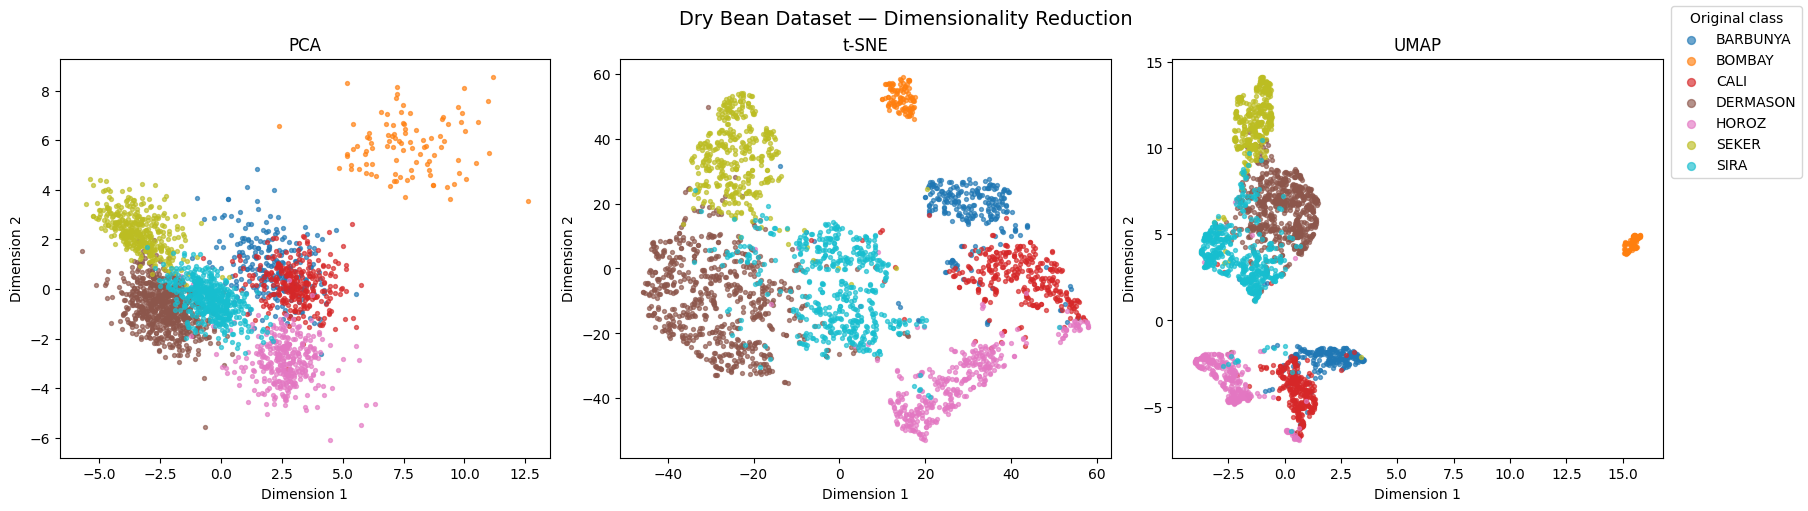

In [62]:
# Apply dimensionality reduction
bean_embeddings = run_dimensionality_reduction(X_bean)

# Visualize results
plot_dimensionality_reduction(
    bean_embeddings,
    y_bean,
    "Dry Bean Dataset"
)

### 4.3 Dimensionality Reduction Discussion

**PCA**

PCA produces a relatively clear representation of several bean varieties.

The Bombay variety forms a distinct group toward the upper-right region of the visualization. Seker and Horoz also occupy recognizable regions, although some observations overlap with other varieties.

However, Barbunya and Cali overlap considerably, while Dermason and Sira also share parts of the central region.

The first two principal components explain 82.21% of the total variance, which is considerably higher than for the other two datasets.

This indicates that a large proportion of the original variation in the bean measurements can be represented using only two dimensions.

**t-SNE**

t-SNE produces more distinct groups than PCA for several bean varieties.

Bombay forms a compact and clearly isolated group near the top of the visualization. Barbunya, Cali, Horoz, and Seker also occupy recognizable regions.

However, Barbunya and Cali overlap substantially, while Dermason and Sira are spread across nearby regions with some mixing.

Compared with PCA, t-SNE reveals more detailed local structures and produces more separated groups for several classes.

**UMAP**

UMAP produces several compact and recognizable groups.

Bombay is clearly separated from the remaining bean varieties, appearing as an isolated group on the right side of the visualization.

Other varieties form multiple groups, with Barbunya, Cali, and Horoz occupying nearby regions in the lower part of the plot. Dermason, Seker, and Sira occupy regions toward the upper-left and central areas, with some overlap.

Although UMAP produces compact groups, several bean classes remain mixed, and the representation appears more compressed than the t-SNE visualization.

**Comparison**

All three techniques reveal meaningful structures within the Dry Bean dataset.

PCA performs particularly well compared with the other two datasets, explaining 82.21% of the total variance and separating several bean varieties.

t-SNE provides the clearest overall visual separation between most bean varieties, although some classes still overlap.

UMAP also produces recognizable groups and clearly isolates Bombay, but several other varieties remain mixed in nearby regions.

For this dataset, t-SNE appears to provide the clearest overall class separation, while PCA provides a useful representation of the broader variation in the numerical measurements.

The results suggest that the bean varieties have distinguishable geometric characteristics, although some varieties share similar measurements.

### 4.4 Clustering

K-Means, DBSCAN, and Hierarchical Clustering are applied to the original standardized 16-dimensional bean measurements.

K-Means and Hierarchical Clustering are configured to identify seven clusters, corresponding to the seven known bean varieties.

DBSCAN identifies density-based groups without requiring the number of clusters to be specified.

The clustering results are visualized using PCA, while the algorithms themselves operate on the original standardized features.

Cross-tabulation tables are used to compare the identified clusters with the seven original bean classes.

DBSCAN eps: 1.532
DBSCAN min_samples: 10

K-Means
Clusters: 7
Noise observations: 0

DBSCAN
Clusters: 2
Noise observations: 116

Hierarchical
Clusters: 7
Noise observations: 0


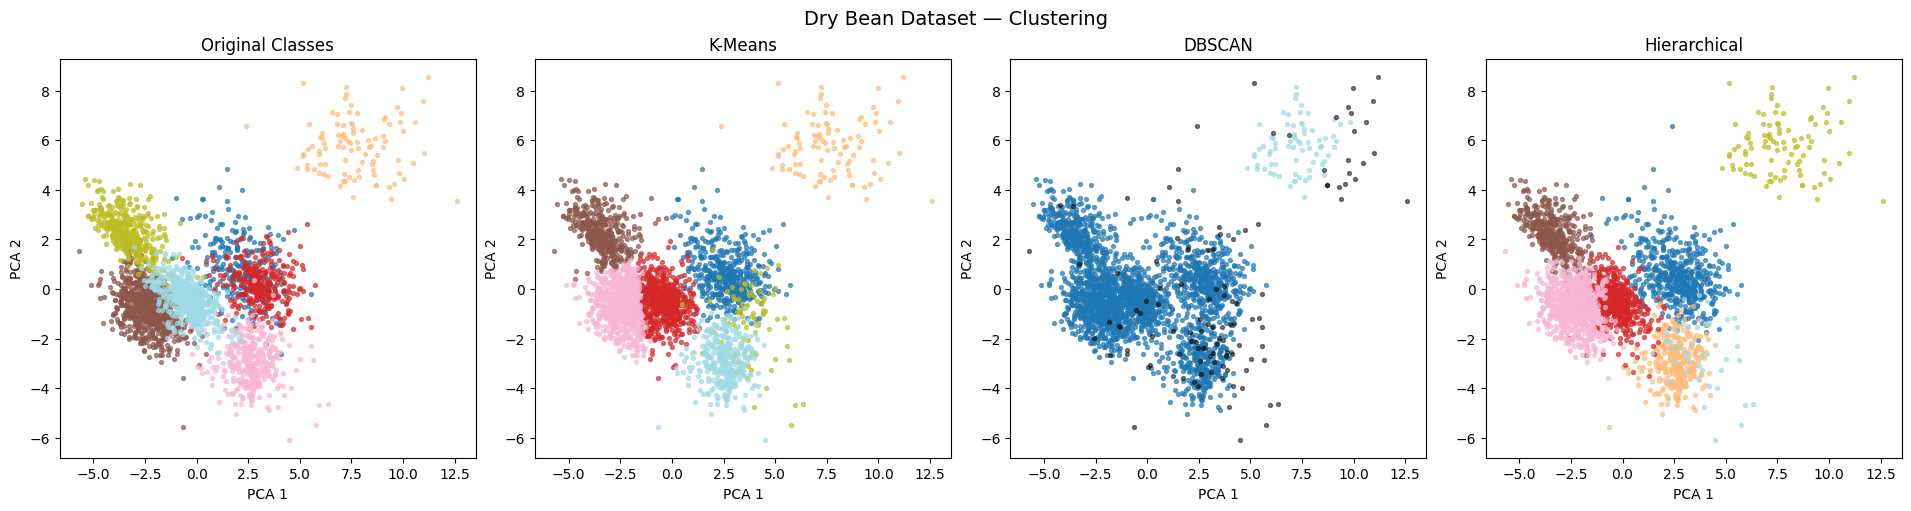


K-Means — Cluster/Class Comparison


Original Class,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA
Cluster,,,,,,,
0,217,0,236,0,2,0,2
1,0,96,0,0,0,0,0
2,17,0,9,90,7,10,420
3,3,0,0,26,0,354,4
4,0,0,0,537,1,10,49
5,7,0,46,0,32,0,2
6,0,0,10,2,301,0,10


Dominant class in each cluster:
{0: 'CALI', 1: 'BOMBAY', 2: 'SIRA', 3: 'SEKER', 4: 'DERMASON', 5: 'CALI', 6: 'HOROZ'}

DBSCAN — Cluster/Class Comparison


Original Class,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA
Cluster,,,,,,,
-1,21,24,10,13,40,2,6
0,223,0,291,642,303,372,481
1,0,72,0,0,0,0,0


Dominant class in each cluster:
{-1: 'HOROZ', 0: 'DERMASON', 1: 'BOMBAY'}

Hierarchical — Cluster/Class Comparison


Original Class,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA
Cluster,,,,,,,
0,230,1,277,0,5,3,8
1,0,0,8,1,294,0,7
2,12,0,8,36,12,7,388
3,0,0,0,20,0,360,8
4,0,0,0,598,2,4,75
5,0,95,0,0,0,0,0
6,2,0,8,0,30,0,1


Dominant class in each cluster:
{0: 'CALI', 1: 'HOROZ', 2: 'SIRA', 3: 'SEKER', 4: 'DERMASON', 5: 'BOMBAY', 6: 'HOROZ'}


In [63]:
# Apply clustering
bean_clusters = run_clustering(
    X_bean,
    n_classes=len(np.unique(y_bean))
)

# Visualize clustering results
plot_clustering(
    bean_embeddings,
    bean_clusters,
    y_bean,
    "Dry Bean Dataset"
)

# Compare clusters with original labels
compare_clusters(
    bean_clusters,
    y_bean
)

### 4.5 Clustering Discussion

**K-Means**

K-Means produces seven clusters, corresponding to the seven known bean varieties.

Several clusters are dominated by individual varieties. Cluster 1 contains all 96 Bombay observations and no observations from other classes, making it a perfectly homogeneous cluster within the selected sample.

Cluster 3 contains 354 Seker observations, cluster 4 contains 537 Dermason observations, and cluster 6 contains 301 Horoz observations.

However, some varieties are mixed. Cluster 0 contains 217 Barbunya and 236 Cali observations, indicating that these varieties have similar numerical characteristics.

Sira is also mixed with several other varieties in cluster 2, although it represents the majority of that cluster.

Overall, K-Means identifies several meaningful groups, but it does not clearly distinguish between all seven bean varieties.

**DBSCAN**

DBSCAN identifies two clusters and classifies 116 observations as noise, using an estimated eps value of 1.532 and min_samples=10.

Cluster 1 contains 72 Bombay observations and no observations from other bean varieties, indicating that DBSCAN identifies a particularly dense group belonging to Bombay.

However, cluster 0 contains 2,312 observations from the other varieties, including Barbunya, Cali, Dermason, Horoz, Seker, and Sira.

The noise observations include all seven varieties, with Horoz and Bombay representing substantial portions of the noise group.

Although DBSCAN successfully identifies part of the Bombay class as a separate cluster, it fails to distinguish most other bean varieties with the selected parameters.

**Hierarchical Clustering**

Hierarchical Clustering produces seven clusters using Ward linkage.

Several clusters correspond closely to individual bean varieties.

Cluster 5 contains 95 Bombay observations and no observations from other classes. Cluster 1 contains 294 Horoz observations, while cluster 3 contains 360 Seker observations.

Cluster 4 is dominated by Dermason, containing 598 observations of this variety.

However, cluster 0 contains 230 Barbunya and 277 Cali observations, indicating that these varieties are difficult to separate.

Cluster 2 is dominated by Sira but also contains observations from other varieties.

Hierarchical Clustering therefore identifies several meaningful groups, although some classes remain mixed.

**Comparison**

K-Means and Hierarchical Clustering both produce substantially more meaningful results than DBSCAN.

Both methods clearly identify the Bombay variety and produce clusters dominated by Seker, Dermason, and Horoz.

Hierarchical Clustering appears to provide slightly more meaningful overall separation, particularly for Dermason, Seker, and Horoz.

K-Means produces comparable results but divides some varieties across several clusters.

DBSCAN identifies a distinct Bombay group but combines most remaining observations into one large cluster.

Based on the cross-tabulation tables and visualizations, Hierarchical Clustering appears to provide the most meaningful overall clustering for the Dry Bean dataset.

The results also demonstrate that Barbunya and Cali are difficult to separate using their numerical shape characteristics.

## 5. Overall Comparison

The three datasets contain different types of observations and numbers of classes.

Pen Digits contains handwriting coordinates representing ten digits, Cardiotocography contains fetal monitoring measurements with three classes, and Dry Bean contains numerical shape measurements representing seven bean varieties.

The same dimensionality reduction and clustering techniques were applied to each dataset, allowing their results to be compared.

### 5.1 Dimensionality Reduction Comparison

| Dataset | PCA Explained Variance | Clearest Separation |
|---|---|---|
| Pen Digits | 49.63% | UMAP |
| Cardiotocography | 45.30% | UMAP (local structures, but substantial class overlap) |
| Dry Bean | 82.21% | t-SNE |

**Pen Digits**

PCA shows considerable overlap between the handwritten digit classes, while t-SNE and UMAP reveal more distinct groups. UMAP provides the clearest overall visual separation.

**Cardiotocography**

All three techniques show considerable overlap between the Normal, Suspect, and Pathologic categories. UMAP reveals recognizable local structures, but no technique clearly separates all three classes.

**Dry Bean**

PCA performs particularly well, explaining 82.21% of the total variance and separating several bean varieties. t-SNE provides the clearest overall visual separation, while UMAP also reveals meaningful groups.

**Comparison**

The results show that no dimensionality reduction technique is necessarily the clearest for every dataset.

PCA is particularly effective when a large proportion of the original variance can be represented in two dimensions, as demonstrated by the Dry Bean dataset.

t-SNE and UMAP reveal more detailed local structures, which can be especially useful when the relationships between observations are nonlinear.

However, visually distinct groups do not necessarily indicate that the same structures are equally well separated in the original multidimensional feature space.

### 5.2 Clustering Comparison

| Dataset | Most Meaningful Clustering | Main Observation |
|---|---|---|
| Pen Digits | K-Means | Several digit classes are successfully grouped, but some remain mixed |
| Cardiotocography | K-Means | Identifies Normal-dominated and Pathologic-enriched groups |
| Dry Bean | Hierarchical Clustering | Several bean varieties form relatively homogeneous clusters |

**Pen Digits**

K-Means and Hierarchical Clustering both identify meaningful groups corresponding to several original digit classes. K-Means appears to produce the most useful overall clustering, while DBSCAN assigns most observations to one large cluster.

**Cardiotocography**

K-Means and Hierarchical Clustering both identify some differences between fetal-state categories, although considerable overlap remains. K-Means appears slightly more meaningful overall, while DBSCAN produces only one cluster.

**Dry Bean**

K-Means and Hierarchical Clustering both identify several bean varieties successfully. Hierarchical Clustering provides slightly clearer separation for some varieties, while DBSCAN mainly separates part of the Bombay class from the remaining observations.

**Comparison**

The most meaningful clustering algorithm differs depending on the dataset.

K-Means performs relatively well on Pen Digits and Cardiotocography, while Hierarchical Clustering provides slightly more meaningful results for Dry Bean.

DBSCAN produces comparatively poor separation across all three datasets with the selected parameters. This does not mean DBSCAN is generally unsuitable for these datasets, since different parameter settings could produce different results.

### 5.3 Differences Between Datasets

Several characteristics help explain the differences between the results.

**Number of classes**

Pen Digits contains ten classes, Cardiotocography contains three, and Dry Bean contains seven. The different numbers of classes affect how many groups the algorithms are expected to identify.

**Feature characteristics**

Pen Digits contains coordinate measurements representing handwriting trajectories. Different digits can have similar shapes, causing observations from different classes to overlap.

Cardiotocography contains fetal monitoring measurements. The original fetal-state categories overlap considerably in the feature space, making it difficult for unsupervised algorithms to identify three distinct groups.

Dry Bean contains geometric measurements describing bean shapes and sizes. Several varieties have distinguishable characteristics, making some groups easier to identify.

**Class distribution**

The Cardiotocography dataset contains considerably more Normal observations than Suspect or Pathologic observations. This imbalance may influence the clusters identified by the algorithms.

**Algorithm assumptions**

K-Means and Hierarchical Clustering are configured to produce a predefined number of groups. DBSCAN instead identifies clusters based on density and may classify some observations as noise.

These differences help explain why the algorithms produce different results across the datasets.

## 6. Conclusion

This assignment investigated three dimensionality reduction techniques and three clustering algorithms using the Pen-Based Recognition of Handwritten Digits, Cardiotocography, and Dry Bean datasets.

PCA, t-SNE, and UMAP were used to reduce the original multidimensional observations to two-dimensional representations. K-Means, DBSCAN, and Hierarchical Clustering were applied to the original standardized features, and the resulting clusters were compared with the known class labels.

### Main Findings

**Dimensionality Reduction**

UMAP provided the clearest visual separation for Pen Digits, while t-SNE produced the most distinguishable overall groups for Dry Bean.

For Cardiotocography, all three methods showed considerable overlap between the original classes, although UMAP revealed recognizable local structures.

PCA explained 49.63% of the variance for Pen Digits, 45.30% for Cardiotocography, and 82.21% for Dry Bean.

The results demonstrate that dimensionality reduction techniques reveal different aspects of a dataset and that no single technique necessarily produces the clearest representation in every situation.

**Clustering**

K-Means appeared to produce the most meaningful overall clusters for Pen Digits and Cardiotocography, while Hierarchical Clustering provided slightly more meaningful results for Dry Bean.

Both K-Means and Hierarchical Clustering successfully identified several groups corresponding to the original classes, although overlapping classes remained a challenge.

DBSCAN produced comparatively poor results across the three datasets with the selected parameters, generally combining most observations into one large cluster.

### Limitations

The analysis used stratified samples of up to 2,500 observations for computational efficiency. Consequently, the results may not represent every pattern found in the complete datasets.

The clustering results also depend on the selected parameters and assumptions of each algorithm.

K-Means and Hierarchical Clustering were configured to identify the same number of clusters as the known classes, while DBSCAN determined the number of clusters automatically.

The comparisons were based on visual inspection and cross-tabulation tables rather than quantitative clustering or dimensionality reduction quality measures.

Furthermore, clear separation in two-dimensional visualizations does not necessarily imply equally clear separation in the original multidimensional feature space.

### Final Conclusion

The results demonstrate that dimensionality reduction and clustering can reveal meaningful structures in multidimensional datasets, but their effectiveness depends on the characteristics of the data.

Nonlinear dimensionality reduction methods generally produced clearer visual groups, while K-Means and Hierarchical Clustering identified more meaningful clusters than DBSCAN with the selected configurations.

The analysis also shows that clustering results do not necessarily correspond perfectly to the original class labels, particularly when different classes share similar numerical characteristics.